# Axion Turbidity Forecasting

|Nama | NRP|
|---|---|
|Fa'iz Akbar Hizbullah | 5054241005|
|Shabrina Sarayati | 5054241009|
|Sultan Hamdi Jailani Daulay | 5054241013|
|Muhammad Dayyan Ghazanfar Latief | 5054241036|
|Sitti Aminah | 5054241041|

- Sequence: multivariate time-series sensor windows + RNN family
- Objective: regression (`Turbidity`) with RNN, LSTM, GRU, BiLSTM, BiGRU
- Dataset Source: [Kaggle Competition](https://www.kaggle.com/competitions/axion-competition-2025)


In [1]:
import gc
import json
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

class Log1pScaler:
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
        return np.log1p(np.maximum(X, 0.0))
    def inverse_transform(self, X):
        X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
        X = np.clip(X, 0.0, 12.0)
        return np.expm1(X)

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import Bidirectional, Concatenate, Dense, Dropout, GRU, Input, LSTM, SimpleRNN
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import AdamW

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


2026-04-25 16:13:10.389635: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777133590.655390      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777133590.727193      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777133591.404476      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777133591.404563      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777133591.404567      16 computation_placer.cc:177] computation placer alr

In [2]:
SEED = 42
SEQ_LEN = 144
BATCH_SIZE = 128
EPOCHS = 30
PATIENCE = 4
LR = 1e-3
WEIGHT_DECAY = 1e-4
CLIPNORM = 1.0

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_ROOT = Path("/kaggle/input/competitions/axion-competition-2025")
TRAIN_PATH = DATA_ROOT / "train.csv"
TEST_PATH = DATA_ROOT / "test.csv"
SAMPLE_SUB_PATH = DATA_ROOT / "sample_submission.csv"

OUTPUT_ROOT = Path(".")
ARTIFACT_DIR = OUTPUT_ROOT / "artifacts_axion_rnn"
MODEL_DIR = ARTIFACT_DIR / "models"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.19.0
GPU available: False


2026-04-25 16:13:42.912830: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_sub = pd.read_csv(SAMPLE_SUB_PATH)

train_df["Timestamp"] = pd.to_datetime(train_df["Timestamp"])
test_df["Timestamp"] = pd.to_datetime(test_df["Timestamp"])

train_df = train_df.sort_values("Record number").reset_index(drop=True)
test_df = test_df.sort_values("Record number").reset_index(drop=True)

display(train_df.head())
display(test_df.head())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Sample submission shape:", sample_sub.shape)


,Timestamp,Record number,Average Water Speed,Average Water Direction,Chlorophyll,Temperature,Dissolved Oxygen,Dissolved Oxygen (%Saturation),pH,Salinity,Specific Conductance,Turbidity
0,2023-08-04 23:00:00,1468,4.834,73.484,1.621,20.018,7.472,101.175,8.176,35.215,53.262,2.068
1,2023-08-04 23:30:00,1469,2.544,106.424,1.959,19.986,7.455,100.884,8.175,35.209,53.254,1.994
2,2023-08-04 23:00:00,1470,1.260,156.755,1.620,20.001,7.430,100.571,8.171,35.207,53.252,2.030
3,2023-08-04 23:30:00,1471,0.760,281.754,1.761,19.983,7.419,100.398,8.171,35.211,53.257,1.973
4,2023-08-04 23:00:00,1472,3.397,244.637,1.635,19.986,7.429,100.538,8.171,35.208,53.253,1.944


,Timestamp,Record number,Average Water Speed,Average Water Direction,Chlorophyll,Temperature,Dissolved Oxygen,Dissolved Oxygen (%Saturation),pH,Salinity,Specific Conductance
0,2024-12-01 00:00:00,54916,84.585,80.849,1.172,25.513,5.407,73.216,7.901,18.230,29.510
1,2024-12-01 00:10:00,54917,NaN,81.950,1.203,25.529,5.497,74.441,7.908,18.141,29.379
2,2024-12-01 00:20:00,54918,NaN,84.333,1.184,25.494,5.505,74.177,7.873,17.384,28.260
3,2024-12-01 00:30:00,54919,NaN,83.426,1.172,25.537,5.473,74.321,7.902,18.660,30.142
4,2024-12-01 00:40:00,54920,NaN,81.562,1.240,25.536,5.432,73.530,7.881,18.077,29.284


Train shape: (53448, 12)
Test shape: (14610, 11)
Sample submission shape: (14610, 2)


## EDA


,train_null,test_null
Temperature,9214,4
Turbidity,6066,0
Dissolved Oxygen (%Saturation),5758,576
Dissolved Oxygen,4309,6
Salinity,3967,163
Chlorophyll,1704,6
Specific Conductance,1376,64
pH,1093,33
Average Water Speed,219,863
Average Water Direction,1,0


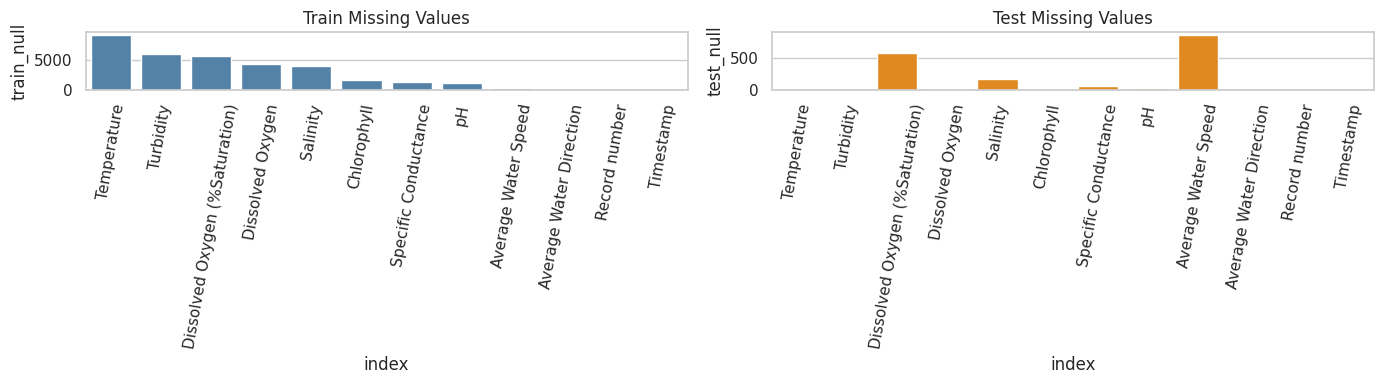

Target count: 47382
count    47382.000000
mean         4.637636
std          4.486299
min          0.075000
25%          2.537000
50%          3.439000
75%          5.135000
max         49.984000
Name: Turbidity, dtype: float64


In [4]:
null_summary = pd.DataFrame({
    "train_null": train_df.isna().sum(),
    "test_null": test_df.isna().sum()
}).fillna(0).astype(int).sort_values("train_null", ascending=False)

display(null_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=null_summary.reset_index(), x="index", y="train_null", ax=axes[0], color="steelblue")
axes[0].set_title("Train Missing Values")
axes[0].tick_params(axis="x", rotation=80)
sns.barplot(data=null_summary.reset_index(), x="index", y="test_null", ax=axes[1], color="darkorange")
axes[1].set_title("Test Missing Values")
axes[1].tick_params(axis="x", rotation=80)
plt.tight_layout()
plt.show()

target_non_null = train_df["Turbidity"].dropna()
print("Target count:", len(target_non_null))
print(target_non_null.describe())


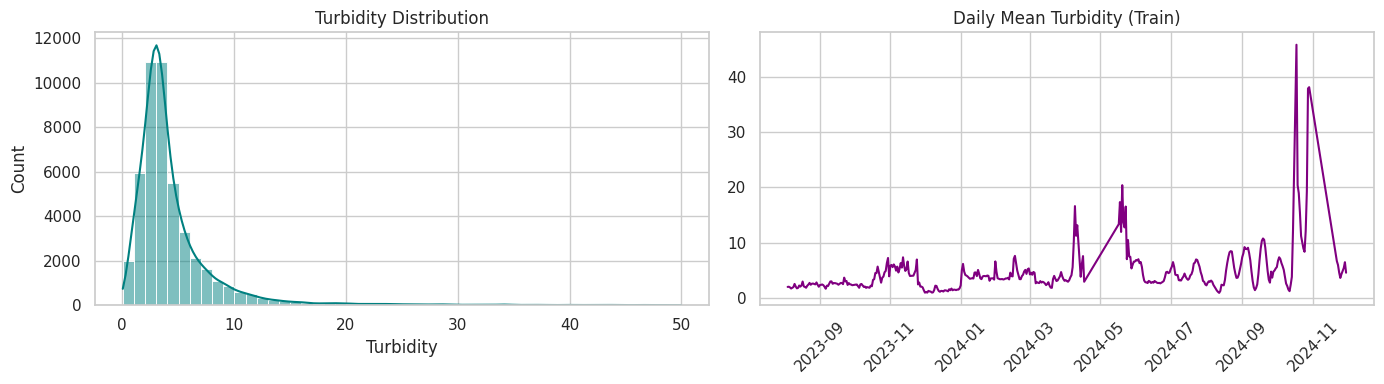

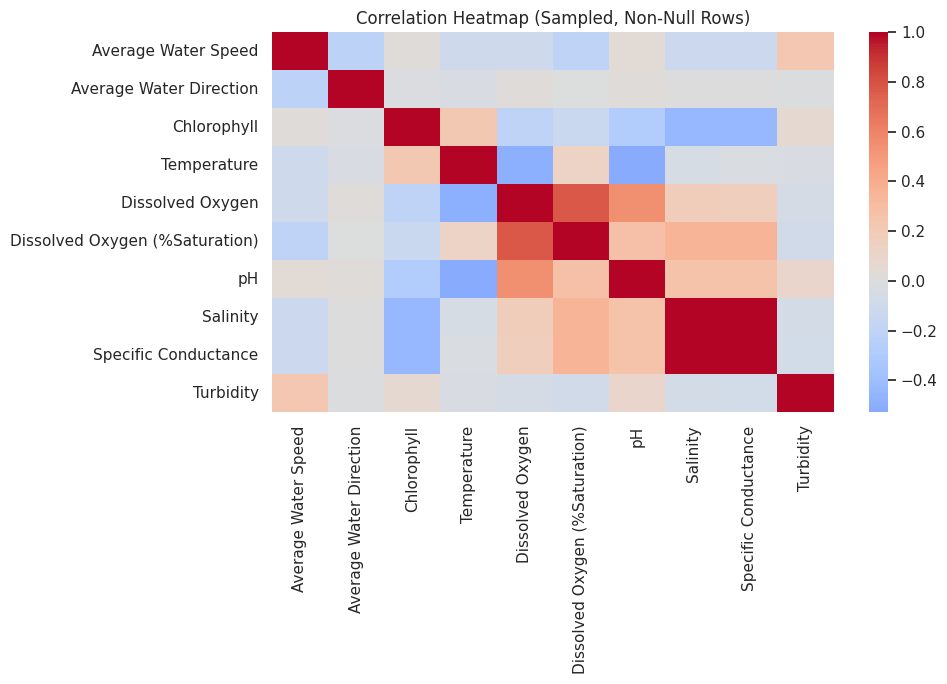

In [5]:
eda_df = train_df.dropna(subset=["Turbidity"]).copy()
eda_df["date"] = eda_df["Timestamp"].dt.date
daily_target = eda_df.groupby("date")["Turbidity"].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(eda_df["Turbidity"], bins=50, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Turbidity Distribution")
axes[0].set_xlabel("Turbidity")

axes[1].plot(daily_target["date"], daily_target["Turbidity"], color="purple")
axes[1].set_title("Daily Mean Turbidity (Train)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

corr_cols = [c for c in train_df.columns if c not in ["Timestamp", "Record number"]]
corr_df = train_df[corr_cols].copy().dropna()
if len(corr_df) > 1000:
    corr_df = corr_df.sample(1000, random_state=SEED)

plt.figure(figsize=(10, 7))
sns.heatmap(corr_df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Sampled, Non-Null Rows)")
plt.tight_layout()
plt.show()


## Preprocessing


In [6]:
train_tag = train_df.assign(_is_train=1)
test_tag = test_df.assign(_is_train=0)
full_df = pd.concat([train_tag, test_tag], axis=0, ignore_index=True)

base_feature_cols = [
    "Average Water Speed",
    "Average Water Direction",
    "Chlorophyll",
    "Temperature",
    "Dissolved Oxygen",
    "Dissolved Oxygen (%Saturation)",
    "pH",
    "Salinity",
    "Specific Conductance",
]

# EDA deep-dive: missing-indicator + top-3 lag terbukti improve (backtest baseline +4.2% vs base).
missing_indicator_cols = []
for col in base_feature_cols:
    ind_col = f"{col}_was_missing"
    full_df[ind_col] = full_df[col].isna().astype(float)
    missing_indicator_cols.append(ind_col)

# Berdasarkan studi preprocessing terpisah: imputasi time interpolation paling stabil.
full_df = full_df.sort_values(["Timestamp", "Record number"]).set_index("Timestamp")
full_df[base_feature_cols] = full_df[base_feature_cols].interpolate(method="time", limit_direction="both")
full_df[base_feature_cols] = full_df[base_feature_cols].ffill().bfill()
full_df = full_df.reset_index().sort_values(["Timestamp", "Record number"]).reset_index(drop=True)

lag_spec = {
    "Average Water Speed": 10,
    "Dissolved Oxygen (%Saturation)": 72,
    "Salinity": 1,
}
lag_feature_cols = []
for col, lag_n in lag_spec.items():
    lag_col = f"{col}_lag_{lag_n}"
    full_df[lag_col] = full_df[col].shift(lag_n)
    lag_feature_cols.append(lag_col)
full_df[lag_feature_cols] = full_df[lag_feature_cols].bfill().ffill()

turbidity_lags = [1, 6, 36]
turbidity_lag_cols = []
for lag_n in turbidity_lags:
    lag_col = f"Turbidity_lag_{lag_n}"
    full_df[lag_col] = full_df["Turbidity"].shift(lag_n)
    turbidity_lag_cols.append(lag_col)

static_feature_cols = base_feature_cols + missing_indicator_cols + lag_feature_cols
feature_cols = static_feature_cols + turbidity_lag_cols

train_full = full_df[full_df["_is_train"] == 1].copy().reset_index(drop=True)
test_full = full_df[full_df["_is_train"] == 0].copy().reset_index(drop=True)

feature_scaler = StandardScaler()
target_scaler = Log1pScaler()

valid_train_target_mask = train_full["Turbidity"].notna().values
feature_fill_values = train_full.loc[valid_train_target_mask, feature_cols].median()
for c in feature_cols:
    full_df[c] = full_df[c].fillna(feature_fill_values[c])

feature_scaler.fit(train_full.loc[valid_train_target_mask, feature_cols])

full_features_scaled = feature_scaler.transform(full_df[feature_cols])
full_aux_scaled = full_features_scaled.copy()

full_target = full_df["Turbidity"].values.astype(float)
all_train_positions = np.where((full_df["_is_train"].values == 1) & (~np.isnan(full_target)))[0]

split_idx = int(len(all_train_positions) * 0.8)
train_positions = all_train_positions[:split_idx]
val_positions = all_train_positions[split_idx:]
test_positions = np.where(full_df["_is_train"].values == 0)[0]
test_record_numbers_seq_order = full_df.loc[test_positions, "Record number"].values

y_train_raw = full_target[train_positions].reshape(-1, 1)
y_val_raw = full_target[val_positions].reshape(-1, 1)
target_scaler.fit(y_train_raw)
target_upper_cap = float(np.nanquantile(y_train_raw, 0.999) * 3.0)
if (not np.isfinite(target_upper_cap)) or (target_upper_cap <= 0):
    target_upper_cap = 200.0
target_log_cap = float(np.log1p(target_upper_cap))


def make_sequences(features, aux, targets, positions, seq_len, fit_target=False):
    xs_seq, xs_aux, ys = [], [], []
    for pos in positions:
        start = pos - seq_len + 1
        if start < 0:
            continue
        seq_x = features[start : pos + 1]
        aux_x = aux[pos]
        if np.isnan(seq_x).any() or np.isnan(aux_x).any():
            continue
        xs_seq.append(seq_x)
        xs_aux.append(aux_x)
        if fit_target:
            ys.append(targets[pos])

    xs_seq = np.asarray(xs_seq, dtype=np.float32)
    xs_aux = np.asarray(xs_aux, dtype=np.float32)
    if fit_target:
        ys = np.asarray(ys, dtype=np.float32).reshape(-1, 1)
        return xs_seq, xs_aux, ys
    return xs_seq, xs_aux


X_train_seq, X_train_aux, y_train_seq_raw = make_sequences(
    full_features_scaled, full_aux_scaled, full_target, train_positions, SEQ_LEN, fit_target=True
)
X_val_seq, X_val_aux, y_val_seq_raw = make_sequences(
    full_features_scaled, full_aux_scaled, full_target, val_positions, SEQ_LEN, fit_target=True
)

y_train = target_scaler.transform(y_train_seq_raw).astype(np.float32)
y_val = target_scaler.transform(y_val_seq_raw).astype(np.float32)

SEQ_DIM = X_train_seq.shape[-1]
AUX_DIM = X_train_aux.shape[-1]

print("Train sequences:", X_train_seq.shape, y_train.shape)
print("Val sequences:", X_val_seq.shape, y_val.shape)
print("SEQ_DIM:", SEQ_DIM, "| AUX_DIM:", AUX_DIM)
print("SEQ_LEN (steps):", SEQ_LEN)
print("Feature cols:", len(feature_cols))
print("Test positions:", len(test_positions), "| Unique record numbers:", pd.Series(test_record_numbers_seq_order).nunique())


Train sequences: (37763, 144, 24) (37763, 1)
Val sequences: (9477, 144, 24) (9477, 1)
SEQ_DIM: 24 | AUX_DIM: 24
SEQ_LEN (steps): 144
Feature cols: 24
Test positions: 14610 | Unique record numbers: 14610


## Util


In [7]:
results = []
histories = {}
val_predictions = {}
trained_models = {}

TRAIN_INPUTS = [X_train_seq, X_train_aux]
VAL_INPUTS = [X_val_seq, X_val_aux]


def compile_model(model):
    model.compile(
        optimizer=AdamW(learning_rate=LR, weight_decay=WEIGHT_DECAY, clipnorm=CLIPNORM),
        loss="mse",
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae"), tf.keras.metrics.RootMeanSquaredError(name="rmse")],
    )
    return model


def fit_and_evaluate(model, model_name):
    best_path = MODEL_DIR / f"{model_name.lower()}_best.keras"
    final_path = MODEL_DIR / f"{model_name.lower()}_final.keras"
    callbacks = [
        EarlyStopping(monitor="val_rmse", mode="min", patience=PATIENCE, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_rmse", mode="min", factor=0.5, patience=1, min_lr=1e-6),
        ModelCheckpoint(filepath=str(best_path), monitor="val_rmse", mode="min", save_best_only=True),
    ]

    history = model.fit(
        TRAIN_INPUTS,
        y_train,
        validation_data=(VAL_INPUTS, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1,
    )

    val_pred_scaled = model.predict(VAL_INPUTS, batch_size=512, verbose=0)
    y_true = target_scaler.inverse_transform(y_val)
    y_pred = target_scaler.inverse_transform(val_pred_scaled)

    val_mae = float(mean_absolute_error(y_true, y_pred))
    val_rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    val_r2 = float(r2_score(y_true, y_pred))

    result = {
        "model": model_name,
        "train_loss_last": float(history.history["loss"][-1]),
        "val_loss_last": float(history.history["val_loss"][-1]),
        "val_mae_last": float(history.history["val_mae"][-1]),
        "val_rmse_last": float(history.history["val_rmse"][-1]),
        "val_mae_eval": val_mae,
        "val_rmse_eval": val_rmse,
        "val_r2_eval": val_r2,
        "best_model_path": str(best_path),
        "final_model_path": str(final_path),
    }

    model.save(final_path)
    return result, history.history, y_pred.reshape(-1)


## Model 1 - RNN


In [8]:
tf.keras.backend.clear_session()
gc.collect()

seq_input = Input(shape=(SEQ_LEN, SEQ_DIM), name="rnn_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="rnn_aux_input")

x = SimpleRNN(64, dropout=0.2)(seq_input)
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
z = Dense(32, activation="relu")(aux_input)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(1, activation="linear")(h)

rnn_model = Model(inputs=[seq_input, aux_input], outputs=out, name="RNN_fusion")
rnn_model = compile_model(rnn_model)
rnn_result, rnn_history, rnn_val_pred = fit_and_evaluate(rnn_model, "RNN")

results.append(rnn_result)
histories["RNN"] = rnn_history
val_predictions["RNN"] = rnn_val_pred
trained_models["RNN"] = rnn_model
display(pd.DataFrame([rnn_result]))


Epoch 1/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - loss: 0.5314 - mae: 0.4917 - rmse: 0.6861 - val_loss: 0.1500 - val_mae: 0.2879 - val_rmse: 0.3873 - learning_rate: 0.0010
Epoch 2/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - loss: 0.1034 - mae: 0.2363 - rmse: 0.3215 - val_loss: 0.1214 - val_mae: 0.2504 - val_rmse: 0.3484 - learning_rate: 0.0010
Epoch 3/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - loss: 0.0830 - mae: 0.2090 - rmse: 0.2881 - val_loss: 0.0957 - val_mae: 0.2163 - val_rmse: 0.3094 - learning_rate: 0.0010
Epoch 4/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 17s 57ms/step - loss: 0.0715 - mae: 0.1907 - rmse: 0.2674 - val_loss: 0.0883 - val_mae: 0.2056 - val_rmse: 0.2971 - learning_rate: 0.0010
Epoch 5/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 56ms/step - loss: 0.0654 - mae: 0.1777 - rmse: 0.2558 - val_loss: 0.0828 - val_mae: 0.1966 - val_rmse: 0.2878 - learning_rate: 0.0010
Epoch 6/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - loss: 0.0741 - mae: 0.1689 - rmse: 0.2715 - val_loss: 

,model,train_loss_last,val_loss_last,val_mae_last,val_rmse_last,val_mae_eval,val_rmse_eval,val_r2_eval,best_model_path,final_model_path
0,RNN,0.049219,0.079361,0.185867,0.281711,1.668616,4.028041,0.56845,artifacts_axion_rnn/models/rnn_best.keras,artifacts_axion_rnn/models/rnn_final.keras


## Model 2 - LSTM


In [9]:
tf.keras.backend.clear_session()
gc.collect()

seq_input = Input(shape=(SEQ_LEN, SEQ_DIM), name="lstm_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="lstm_aux_input")

x = LSTM(64, dropout=0.2)(seq_input)
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
z = Dense(32, activation="relu")(aux_input)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(1, activation="linear")(h)

lstm_model = Model(inputs=[seq_input, aux_input], outputs=out, name="LSTM_fusion")
lstm_model = compile_model(lstm_model)
lstm_result, lstm_history, lstm_val_pred = fit_and_evaluate(lstm_model, "LSTM")

results.append(lstm_result)
histories["LSTM"] = lstm_history
val_predictions["LSTM"] = lstm_val_pred
trained_models["LSTM"] = lstm_model
display(pd.DataFrame([lstm_result]))


Epoch 1/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 68s 215ms/step - loss: 0.4127 - mae: 0.4344 - rmse: 0.6139 - val_loss: 0.1670 - val_mae: 0.2848 - val_rmse: 0.4087 - learning_rate: 0.0010
Epoch 2/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 61s 208ms/step - loss: 0.0971 - mae: 0.2250 - rmse: 0.3116 - val_loss: 0.1231 - val_mae: 0.2504 - val_rmse: 0.3508 - learning_rate: 0.0010
Epoch 3/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 67s 227ms/step - loss: 0.0856 - mae: 0.2033 - rmse: 0.2925 - val_loss: 0.1165 - val_mae: 0.2400 - val_rmse: 0.3414 - learning_rate: 0.0010
Epoch 4/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 64s 216ms/step - loss: 0.0719 - mae: 0.1905 - rmse: 0.2681 - val_loss: 0.1130 - val_mae: 0.2323 - val_rmse: 0.3361 - learning_rate: 0.0010
Epoch 5/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 63s 214ms/step - loss: 0.0677 - mae: 0.1752 - rmse: 0.2601 - val_loss: 0.0911 - val_mae: 0.2101 - val_rmse: 0.3019 - learning_rate: 0.0010
Epoch 6/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 65s 219ms/step - loss: 0.0605 - mae: 0.1677 - rmse: 0.2459 - val_

,model,train_loss_last,val_loss_last,val_mae_last,val_rmse_last,val_mae_eval,val_rmse_eval,val_r2_eval,best_model_path,final_model_path
0,LSTM,0.044199,0.068395,0.171374,0.261524,1.568245,3.918623,0.591577,artifacts_axion_rnn/models/lstm_best.keras,artifacts_axion_rnn/models/lstm_final.keras


## Model 3 - BiLSTM


In [10]:
tf.keras.backend.clear_session()
gc.collect()

seq_input = Input(shape=(SEQ_LEN, SEQ_DIM), name="bilstm_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="bilstm_aux_input")

x = Bidirectional(LSTM(64, dropout=0.2))(seq_input)
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
z = Dense(32, activation="relu")(aux_input)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(1, activation="linear")(h)

bilstm_model = Model(inputs=[seq_input, aux_input], outputs=out, name="BiLSTM_fusion")
bilstm_model = compile_model(bilstm_model)
bilstm_result, bilstm_history, bilstm_val_pred = fit_and_evaluate(bilstm_model, "BiLSTM")

results.append(bilstm_result)
histories["BiLSTM"] = bilstm_history
val_predictions["BiLSTM"] = bilstm_val_pred
trained_models["BiLSTM"] = bilstm_model
display(pd.DataFrame([bilstm_result]))


Epoch 1/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 68s 212ms/step - loss: 0.4999 - mae: 0.4772 - rmse: 0.6613 - val_loss: 0.1384 - val_mae: 0.2740 - val_rmse: 0.3721 - learning_rate: 0.0010
Epoch 2/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 64s 215ms/step - loss: 0.0989 - mae: 0.2278 - rmse: 0.3145 - val_loss: 0.0991 - val_mae: 0.2226 - val_rmse: 0.3148 - learning_rate: 0.0010
Epoch 3/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 62s 209ms/step - loss: 0.0807 - mae: 0.2037 - rmse: 0.2840 - val_loss: 0.0880 - val_mae: 0.2037 - val_rmse: 0.2967 - learning_rate: 0.0010
Epoch 4/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 62s 209ms/step - loss: 0.0835 - mae: 0.1897 - rmse: 0.2884 - val_loss: 0.0856 - val_mae: 0.1989 - val_rmse: 0.2926 - learning_rate: 0.0010
Epoch 5/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 62s 210ms/step - loss: 0.0641 - mae: 0.1764 - rmse: 0.2531 - val_loss: 0.0797 - val_mae: 0.1926 - val_rmse: 0.2824 - learning_rate: 0.0010
Epoch 6/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 61s 206ms/step - loss: 0.0602 - mae: 0.1681 - rmse: 0.2453 - val_

,model,train_loss_last,val_loss_last,val_mae_last,val_rmse_last,val_mae_eval,val_rmse_eval,val_r2_eval,best_model_path,final_model_path
0,BiLSTM,0.049143,0.076499,0.185547,0.276584,1.716772,4.023132,0.569501,artifacts_axion_rnn/models/bilstm_best.keras,artifacts_axion_rnn/models/bilstm_final.keras


## Model 4 - GRU


In [11]:
tf.keras.backend.clear_session()
gc.collect()

seq_input = Input(shape=(SEQ_LEN, SEQ_DIM), name="gru_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="gru_aux_input")

x = GRU(64, dropout=0.2)(seq_input)
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
z = Dense(32, activation="relu")(aux_input)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(1, activation="linear")(h)

gru_model = Model(inputs=[seq_input, aux_input], outputs=out, name="GRU_fusion")
gru_model = compile_model(gru_model)
gru_result, gru_history, gru_val_pred = fit_and_evaluate(gru_model, "GRU")

results.append(gru_result)
histories["GRU"] = gru_history
val_predictions["GRU"] = gru_val_pred
trained_models["GRU"] = gru_model
display(pd.DataFrame([gru_result]))


Epoch 1/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 62s 195ms/step - loss: 0.3778 - mae: 0.4341 - rmse: 0.5901 - val_loss: 0.1543 - val_mae: 0.2857 - val_rmse: 0.3928 - learning_rate: 0.0010
Epoch 2/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 57s 192ms/step - loss: 0.0955 - mae: 0.2244 - rmse: 0.3090 - val_loss: 0.1202 - val_mae: 0.2511 - val_rmse: 0.3466 - learning_rate: 0.0010
Epoch 3/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 57s 193ms/step - loss: 0.0800 - mae: 0.1998 - rmse: 0.2827 - val_loss: 0.0920 - val_mae: 0.2114 - val_rmse: 0.3033 - learning_rate: 0.0010
Epoch 4/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 57s 191ms/step - loss: 0.0711 - mae: 0.1856 - rmse: 0.2666 - val_loss: 0.0922 - val_mae: 0.2110 - val_rmse: 0.3037 - learning_rate: 0.0010
Epoch 5/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 57s 194ms/step - loss: 0.0632 - mae: 0.1719 - rmse: 0.2513 - val_loss: 0.0926 - val_mae: 0.2100 - val_rmse: 0.3043 - learning_rate: 5.0000e-04
Epoch 6/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 57s 194ms/step - loss: 0.0583 - mae: 0.1643 - rmse: 0.2413 - 

,model,train_loss_last,val_loss_last,val_mae_last,val_rmse_last,val_mae_eval,val_rmse_eval,val_r2_eval,best_model_path,final_model_path
0,GRU,0.053036,0.080998,0.191488,0.284602,1.748369,4.116897,0.549201,artifacts_axion_rnn/models/gru_best.keras,artifacts_axion_rnn/models/gru_final.keras


## Model 5 - BiGRU


In [12]:
tf.keras.backend.clear_session()
gc.collect()

seq_input = Input(shape=(SEQ_LEN, SEQ_DIM), name="bigru_seq_input")
aux_input = Input(shape=(AUX_DIM,), name="bigru_aux_input")

x = Bidirectional(GRU(64, dropout=0.2))(seq_input)
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
z = Dense(32, activation="relu")(aux_input)
h = Concatenate()([x, z])
h = Dense(64, activation="relu")(h)
h = Dropout(0.2)(h)
out = Dense(1, activation="linear")(h)

bigru_model = Model(inputs=[seq_input, aux_input], outputs=out, name="BiGRU_fusion")
bigru_model = compile_model(bigru_model)
bigru_result, bigru_history, bigru_val_pred = fit_and_evaluate(bigru_model, "BiGRU")

results.append(bigru_result)
histories["BiGRU"] = bigru_history
val_predictions["BiGRU"] = bigru_val_pred
trained_models["BiGRU"] = bigru_model
display(pd.DataFrame([bigru_result]))


Epoch 1/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 75s 234ms/step - loss: 0.5197 - mae: 0.4825 - rmse: 0.6824 - val_loss: 0.1937 - val_mae: 0.3314 - val_rmse: 0.4401 - learning_rate: 0.0010
Epoch 2/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 68s 231ms/step - loss: 0.1001 - mae: 0.2327 - rmse: 0.3164 - val_loss: 0.1456 - val_mae: 0.2788 - val_rmse: 0.3815 - learning_rate: 0.0010
Epoch 3/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 69s 233ms/step - loss: 0.0829 - mae: 0.2070 - rmse: 0.2879 - val_loss: 0.1236 - val_mae: 0.2564 - val_rmse: 0.3515 - learning_rate: 0.0010
Epoch 4/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 72s 242ms/step - loss: 0.0718 - mae: 0.1900 - rmse: 0.2680 - val_loss: 0.1045 - val_mae: 0.2325 - val_rmse: 0.3233 - learning_rate: 0.0010
Epoch 5/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 69s 234ms/step - loss: 0.0673 - mae: 0.1775 - rmse: 0.2594 - val_loss: 0.0995 - val_mae: 0.2239 - val_rmse: 0.3154 - learning_rate: 0.0010
Epoch 6/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 69s 234ms/step - loss: 0.0583 - mae: 0.1648 - rmse: 0.2414 - val_

,model,train_loss_last,val_loss_last,val_mae_last,val_rmse_last,val_mae_eval,val_rmse_eval,val_r2_eval,best_model_path,final_model_path
0,BiGRU,0.042713,0.067327,0.164635,0.259474,1.558516,4.010449,0.572212,artifacts_axion_rnn/models/bigru_best.keras,artifacts_axion_rnn/models/bigru_final.keras


## Validation Evaluation


,model,train_loss_last,val_loss_last,val_mae_last,val_rmse_last,val_mae_eval,val_rmse_eval,val_r2_eval,best_model_path,final_model_path
0,LSTM,0.044199,0.068395,0.171374,0.261524,1.568245,3.918623,0.591577,artifacts_axion_rnn/models/lstm_best.keras,artifacts_axion_rnn/models/lstm_final.keras
1,BiGRU,0.042713,0.067327,0.164635,0.259474,1.558516,4.010449,0.572212,artifacts_axion_rnn/models/bigru_best.keras,artifacts_axion_rnn/models/bigru_final.keras
2,BiLSTM,0.049143,0.076499,0.185547,0.276584,1.716772,4.023132,0.569501,artifacts_axion_rnn/models/bilstm_best.keras,artifacts_axion_rnn/models/bilstm_final.keras
3,RNN,0.049219,0.079361,0.185867,0.281711,1.668616,4.028041,0.568450,artifacts_axion_rnn/models/rnn_best.keras,artifacts_axion_rnn/models/rnn_final.keras
4,GRU,0.053036,0.080998,0.191488,0.284602,1.748369,4.116897,0.549201,artifacts_axion_rnn/models/gru_best.keras,artifacts_axion_rnn/models/gru_final.keras


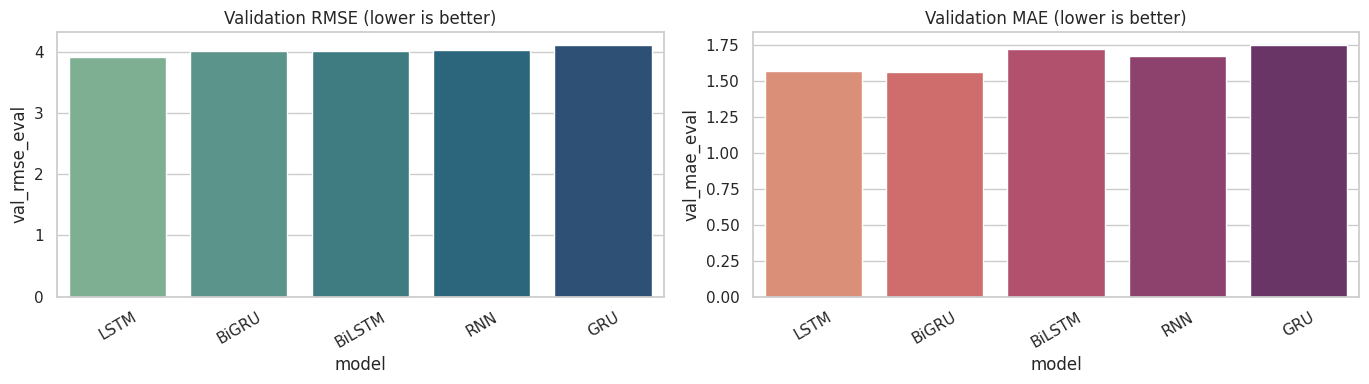

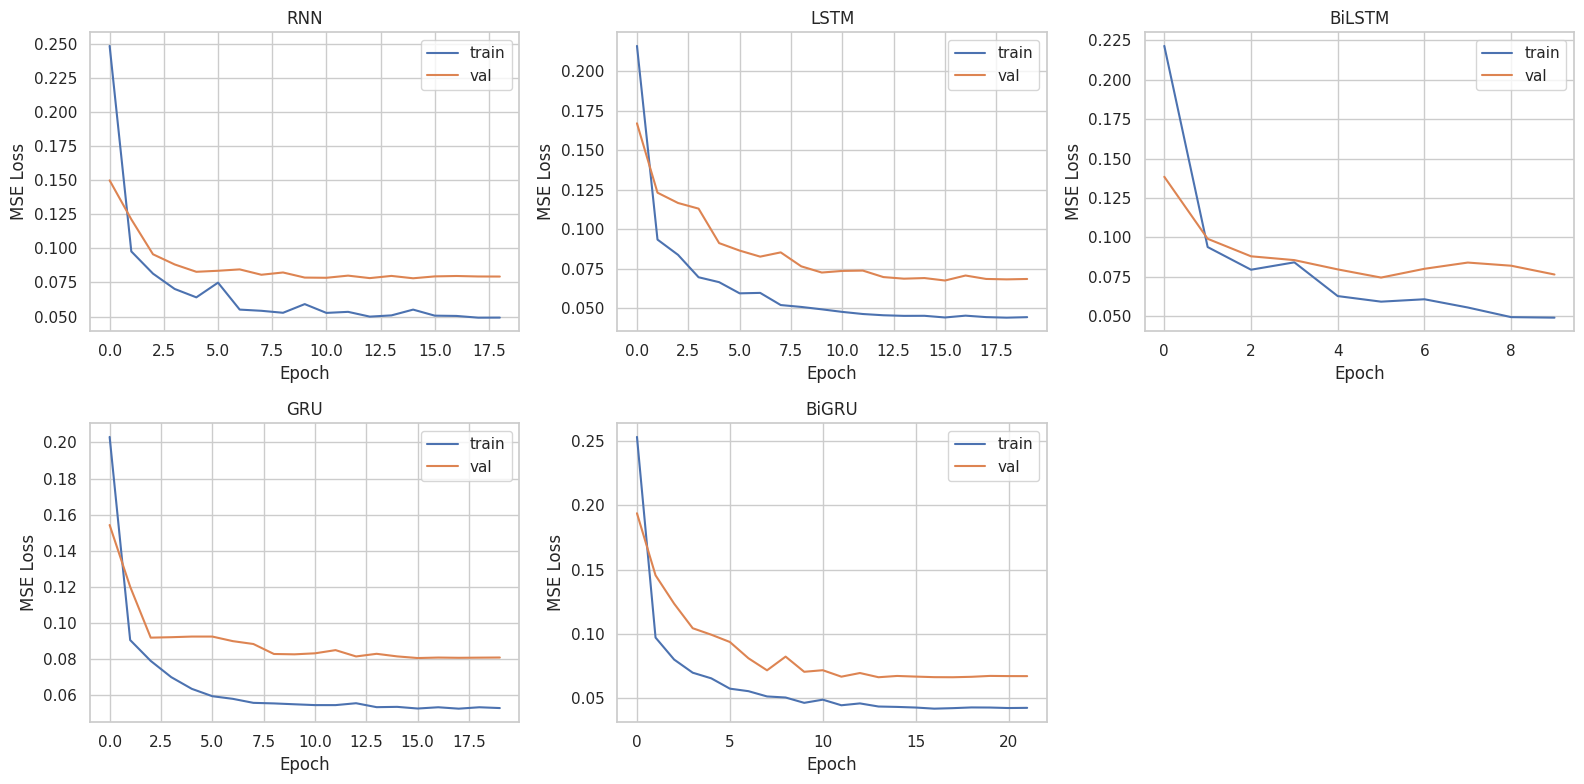

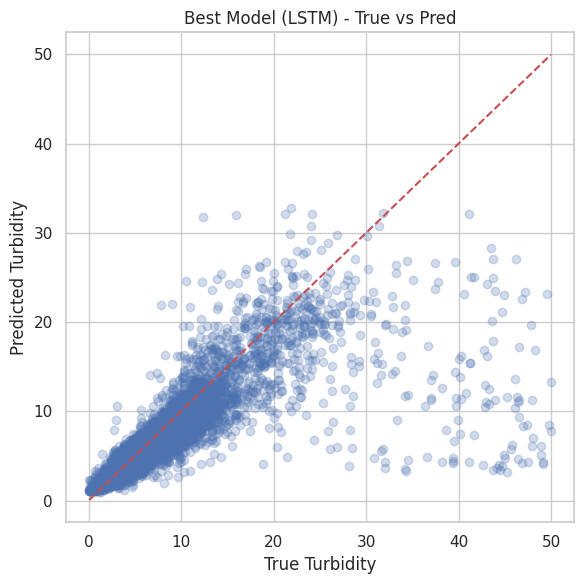

In [13]:
results_df = pd.DataFrame(results).sort_values("val_rmse_eval", ascending=True).reset_index(drop=True)
display(results_df)
results_df.to_csv(ARTIFACT_DIR / "model_comparison_regression.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=results_df, x="model", y="val_rmse_eval", ax=axes[0], palette="crest")
axes[0].set_title("Validation RMSE (lower is better)")
sns.barplot(data=results_df, x="model", y="val_mae_eval", ax=axes[1], palette="flare")
axes[1].set_title("Validation MAE (lower is better)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
model_order = ["RNN", "LSTM", "BiLSTM", "GRU", "BiGRU"]
for i, model_name in enumerate(model_order):
    r, c = divmod(i, 3)
    axes[r, c].plot(histories[model_name]["loss"], label="train")
    axes[r, c].plot(histories[model_name]["val_loss"], label="val")
    axes[r, c].set_title(model_name)
    axes[r, c].set_xlabel("Epoch")
    axes[r, c].set_ylabel("MSE Loss")
    axes[r, c].legend()
axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["model"]
best_val_pred = val_predictions[best_model_name].reshape(-1, 1)
best_val_pred = best_val_pred
y_true_val = target_scaler.inverse_transform(y_val).reshape(-1)
y_pred_val = best_val_pred.reshape(-1)

plt.figure(figsize=(6, 6))
plt.scatter(y_true_val, y_pred_val, alpha=0.25)
low = min(y_true_val.min(), y_pred_val.min())
high = max(y_true_val.max(), y_pred_val.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("True Turbidity")
plt.ylabel("Predicted Turbidity")
plt.title(f"Best Model ({best_model_name}) - True vs Pred")
plt.tight_layout()
plt.show()


## Save


In [14]:
best_model_name = pd.DataFrame(results).sort_values("val_rmse_eval", ascending=True).iloc[0]["model"]
best_model = trained_models[best_model_name]


def recursive_predict_test(model):
    static_mat = full_df[static_feature_cols].values.astype(np.float32)
    turb_filled = full_df["Turbidity"].values.astype(float).copy()
    fill_vals = feature_fill_values.reindex(feature_cols).values.astype(np.float32)
    turbidity_lag_idx = [feature_cols.index(c) for c in turbidity_lag_cols]
    preds = []

    for step, pos in enumerate(test_positions, start=1):
        start = pos - SEQ_LEN + 1
        if start < 0:
            raise ValueError(f"Not enough history for test position {pos}")

        idx = np.arange(start, pos + 1)
        seq_static = static_mat[start : pos + 1]
        lag_arrays = []
        for lag_n in turbidity_lags:
            src = idx - lag_n
            lag_vals = np.where(src >= 0, turb_filled[src], np.nan)
            lag_arrays.append(lag_vals.reshape(-1, 1))

        seq_feat = np.concatenate([seq_static] + lag_arrays, axis=1).astype(np.float32)
        bad_mask = ~np.isfinite(seq_feat)
        if bad_mask.any():
            seq_feat[bad_mask] = np.take(fill_vals, np.where(bad_mask)[1])
        seq_feat[:, turbidity_lag_idx] = np.clip(seq_feat[:, turbidity_lag_idx], 0.0, target_upper_cap)
        seq_feat = np.nan_to_num(seq_feat, nan=0.0, posinf=target_upper_cap, neginf=0.0)

        seq_scaled = feature_scaler.transform(seq_feat).astype(np.float32)
        seq_scaled = np.nan_to_num(seq_scaled, nan=0.0, posinf=1e6, neginf=-1e6)
        seq_in = seq_scaled[np.newaxis, :, :]
        aux_in = seq_scaled[-1, :][np.newaxis, :]

        pred_scaled = model([seq_in, aux_in], training=False).numpy()
        pred_scaled = np.nan_to_num(pred_scaled, nan=0.0, posinf=target_log_cap, neginf=0.0)
        pred_scaled = np.clip(pred_scaled, 0.0, target_log_cap)
        pred_raw = float(target_scaler.inverse_transform(pred_scaled).reshape(-1)[0])
        pred_raw = float(np.clip(np.nan_to_num(pred_raw, nan=0.0, posinf=target_upper_cap, neginf=0.0), 0.0, target_upper_cap))
        turb_filled[pos] = pred_raw
        preds.append(pred_raw)
        if step % 2000 == 0:
            print(f"Recursive inference progress: {step}/{len(test_positions)}")

    return np.asarray(preds, dtype=np.float32)


best_test_pred = recursive_predict_test(best_model)

if len(test_record_numbers_seq_order) != len(best_test_pred):
    raise ValueError(f"Length mismatch: test rows={len(test_record_numbers_seq_order)} vs preds={len(best_test_pred)}")

submission = pd.DataFrame({
    "Record number": test_record_numbers_seq_order,
    "Turbidity": best_test_pred,
}).sort_values("Record number").reset_index(drop=True)

submission_path = ARTIFACT_DIR / "submission_best_sequence_model.csv"
submission.to_csv(submission_path, index=False)

summary = {
    "best_model": best_model_name,
    "artifact_dir": str(ARTIFACT_DIR.resolve()),
    "submission_path": str(submission_path.resolve()),
    "n_train_seq": int(len(X_train_seq)),
    "n_val_seq": int(len(X_val_seq)),
    "n_test_seq": int(len(best_test_pred)),
}

with open(ARTIFACT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

display(submission.head())
print(json.dumps(summary, indent=2))


Recursive inference progress: 2000/14610
Recursive inference progress: 4000/14610
Recursive inference progress: 6000/14610
Recursive inference progress: 8000/14610
Recursive inference progress: 10000/14610
Recursive inference progress: 12000/14610
Recursive inference progress: 14000/14610


,Record number,Turbidity
0,54916,4.746000
1,54917,3.763841
2,54918,4.087697
3,54919,4.041327
4,54920,4.421528


{
  "best_model": "LSTM",
  "artifact_dir": "/kaggle/working/artifacts_axion_rnn",
  "submission_path": "/kaggle/working/artifacts_axion_rnn/submission_best_sequence_model.csv",
  "n_train_seq": 37763,
  "n_val_seq": 9477,
  "n_test_seq": 14610
}
